In [1]:
import numpy as np
import cv2
import matplotlib.pyplot as plt

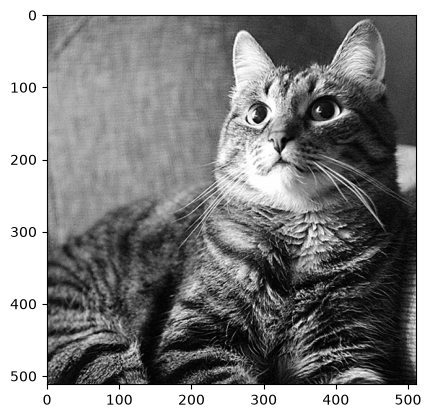

In [2]:
image = cv2.imread('image.jpg', cv2.IMREAD_GRAYSCALE)
plt.imshow(image, cmap='gray')

In [3]:
def haar(image, lvls):
    coeffs = image.astype(np.float32)
    for lvl in range(lvls):
        size = coeffs.shape[0] >> lvl
        block = coeffs[:size, :size]
        block = np.hstack(((block[:, 0::2] + block[:, 1::2]) / 2,
                           (block[:, 0::2] - block[:, 1::2]) / 2))
        coeffs[:size, :size] = np.vstack(((block[0::2] + block[1::2]) / 2,
                                          (block[0::2] - block[1::2]) / 2))
    return coeffs

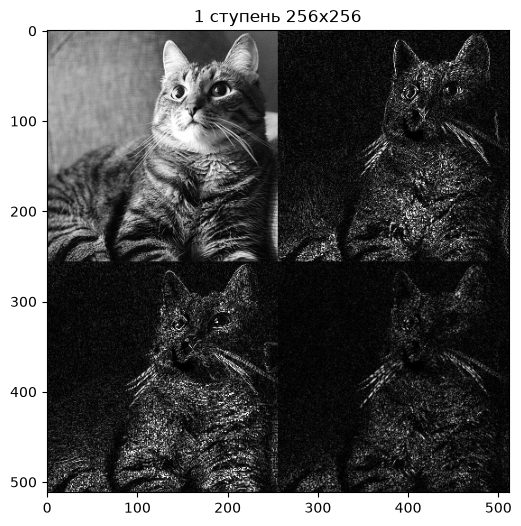

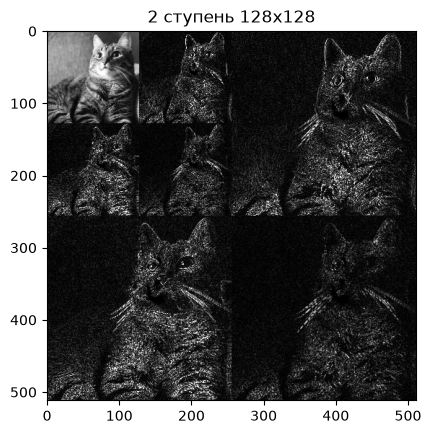

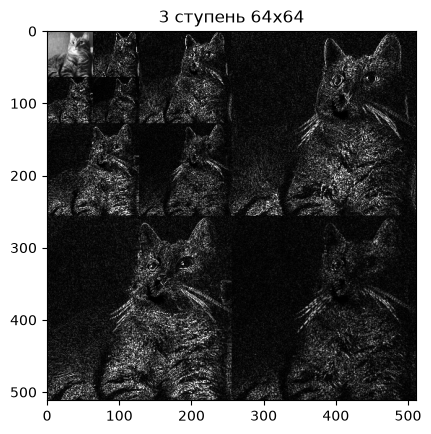

In [5]:
plt.figure(figsize=(18, 6))
for level in range(1, 4):
    coeffs = haar(image, level)
    ll_size = 512 >> level

    vis_img = np.clip(np.abs(coeffs) * 5, 0, 255)
    vis_img[:ll_size, :ll_size] = coeffs[:ll_size, :ll_size]

    plt.imshow(vis_img, cmap='gray')
    plt.title(f'{level} ступень {ll_size}x{ll_size}')
    plt.show()